# Imports

In [1]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers
from keras.utils import image_dataset_from_directory, load_img, img_to_array


from pathlib import Path
from datetime import datetime
import csv

import matplotlib.pyplot as plt
from matplotlib import cm

# Config

In [2]:
IMG_SIZE   = (224, 224)      # matches MobileNetV2 pretraining;
CHANNELS   = 3
BATCH_SIZE = 32
VAL_SPLIT  = 0.2

HEAD_EPOCHS      = 25  # base model epochs
FINETUNE_EPOCHS  = 15   # fine tuning epochs
HEAD_LR          = 1e-3 # set small learning rates
FINETUNE_LR      = 1e-5 
UNFREEZE_FROM    = 100 # unfreeze base.layers[100:]

DROPOUT_RATE = 0.3

# Data

In [3]:
train_ds, val_ds = image_dataset_from_directory("Data", labels='inferred', label_mode='binary',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, validation_split=VAL_SPLIT, subset='both', shuffle=True, seed = 19)

CLASS_NAMES = train_ds.class_names
print("Classes:", CLASS_NAMES)

# let tensorflow decide how many batches of data to fetch ahead of time
AUTOTUNE = tf.data.AUTOTUNE 
# prefetch the appropriate amount
train_ds = train_ds.cache().prefetch(AUTOTUNE) 
val_ds   = val_ds.cache().prefetch(AUTOTUNE)

Found 187 files belonging to 2 classes.
Using 150 files for training.
Using 37 files for validation.
Classes: ['Elephants', 'Village']


# Model

In [4]:
# saves the MobileNetV2 preprocessing function to a shorthand
preprocess = keras.applications.mobilenet_v2.preprocess_input

# load the pretrained MObileNetV2 model and save it
base = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, CHANNELS), # set the image size based on config
    include_top=False, # remove classifier layer, leaving just convolutional layers for extracting features
    weights="imagenet") # use pretrained weights, makes training faster and better for small datasets

base.trainable = False # don't adjust weights for now, just use pretrained ones (protects what it already knnows, doesn't let new, untrained layers ruin the model while they are still learning). Only layers added to this model learn

# entry point of mode, placeholder for an image with characteristics defined by config
inputs = keras.Input(shape=(*IMG_SIZE, CHANNELS), name="image")

# adjust images to prevent overfitting / memorizing images
x = layers.RandomFlip("horizontal")(inputs) # randomly flip some images horizontally
x = layers.RandomRotation(0.08)(x) # randomly rotate some images
x = layers.RandomZoom(0.1)(x) # randomly room in some images
x = layers.RandomContrast(0.1)(x) # randomly adjust the contrast on some images

x = preprocess(x) # adjusts pixels to be in the format MobileNetV2 was trained on

# passes the image through the base model and saves the resulting feature map
#training false to avoid updating stored statistics, keeping the pretraining stable
features = base(x, training=False)

# averages feature map channels, indicates how often a feature appears rather than where it appears
x = layers.GlobalAveragePooling2D()(features) 

# drop a portion of features to stop the model from relying on one feature
x = layers.Dropout(DROPOUT_RATE)(x)

# decision layer, weighted sum of the pooled features, plus a bias
# returns a raw score called a logit
#activation none keep the raw score -> not a probability
logits = layers.Dense(1, activation=None, name="logit")(x)

# assembles the model using the start (inputs) and the end (logits)
# traces backwards from logits to find the in between steps
classifier = keras.Model(inputs, logits, name="elephant_village")

# set what is used to train
classifier.compile(
    # use the Adam optimizer to adjust the neights
    optimizer=keras.optimizers.Adam(HEAD_LR), 
    # use BC to measure how wrong the model was, try to minimize this
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    # display what fraction of images were classified right, threshold 0 means class 1 if the logit is above 0
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy", threshold=0.0)]) 

# Train

## Base

Goal: teach the new head to use the pretrained features for elephant and villages<br>
The base stays frozen, it is not adapted until the finetuning step

In [5]:
# set rules to check at the end of each epoch
callbacks = [
    #monitor validation accuracy, try to maximize accuracy, 
    #stop after 8 epochs with no new best, when it stops, go back to best
    keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=8, restore_best_weights=True),
    # halve the learning rate if the validation loss hasn't improved in 4 epochs
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
]

# train the head of the model
hist_head = classifier.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=callbacks)

Epoch 1/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 317ms/step - accuracy: 0.4258 - loss: 1.1451 - val_accuracy: 0.5135 - val_loss: 0.8131 - learning_rate: 0.0010
Epoch 2/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 197ms/step - accuracy: 0.5646 - loss: 0.7318 - val_accuracy: 0.6757 - val_loss: 0.5764 - learning_rate: 0.0010
Epoch 3/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 197ms/step - accuracy: 0.7343 - loss: 0.5546 - val_accuracy: 0.8378 - val_loss: 0.4280 - learning_rate: 0.0010
Epoch 4/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 197ms/step - accuracy: 0.8750 - loss: 0.3715 - val_accuracy: 0.8919 - val_loss: 0.3278 - learning_rate: 0.0010
Epoch 5/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 197ms/step - accuracy: 0.9457 - loss: 0.2726 - val_accuracy: 0.9189 - val_loss: 0.2587 - learning_rate: 0.0010
Epoch 6/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 194ms/step - accuracy: 0.9227 - loss: 0.2477 - val_accuracy: 0.9189 - val_loss: 0.2144 - learning_rate: 0.0010
Epoch 7/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 202ms/step - accuracy: 0.9344 - loss: 0.1875 - val_accuracy: 

## Finetuning

Goal: update the base to adapt to new data<br>
Important to train the head first because an untrained head would send a lot of randomness into the base model. Once the new head is trained, base can get specalized on the elephant vs village data. These updates are smaller so the base can adapt with a lower risk of losing what it already knows

In [6]:
# unfreeze all base layers
base.trainable = True
for layer in base.layers[:UNFREEZE_FROM]:
    layer.trainable = False # refreeze early layers decided by config

# additionally freeze the batch normalization layers 
# to avoid shifting store statistics and pretrained features
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

#r recompile so changes take effect, with a lower learning rate so updates stay small
classifier.compile(
    optimizer=keras.optimizers.Adam(FINETUNE_LR),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy", threshold=0.0)])

# train again, history saved seperately
hist_ft = classifier.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS, callbacks=callbacks)

Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 338ms/step - accuracy: 0.9820 - loss: 0.0884 - val_accuracy: 1.0000 - val_loss: 0.0573 - learning_rate: 1.0000e-05
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 243ms/step - accuracy: 0.9899 - loss: 0.0597 - val_accuracy: 1.0000 - val_loss: 0.0428 - learning_rate: 1.0000e-05
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 245ms/step - accuracy: 0.9965 - loss: 0.0582 - val_accuracy: 1.0000 - val_loss: 0.0338 - learning_rate: 1.0000e-05
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 245ms/step - accuracy: 0.9947 - loss: 0.0318 - val_accuracy: 1.0000 - val_loss: 0.0304 - learning_rate: 1.0000e-05
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 249ms/step - accuracy: 0.9947 - loss: 0.0263 - val_accuracy: 1.0000 - val_loss: 0.0295 - learning_rate: 1.0000e-05
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 247ms/step - accuracy: 1.0000 - loss: 0.0157 - val_accuracy: 1.0000 - val_loss: 0.0255 - learning_rate: 1.0000e-05
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 243ms/step - accuracy: 1.0000 - loss:

# Heatmap Utilities

In [7]:
# second view of the above model that outputs the feature map and the logit
# shares layers with classifier
grad_model = keras.Model(inputs, [features, logits])

# function to predict a class for an image
def predict_one(path):
    pil = load_img(path, target_size=IMG_SIZE) # takes in image and resizes it for the model
    raw = img_to_array(pil) # convert the image to an array of 0-255 values, no scaling because preprocessing is in the model
    batch = raw[None, ...]# adds a batch dimension, necessary because the model expects many images at once, need to structure a single image like a batch
    logit = float(classifier.predict(batch, verbose=0)[0][0]) # runs the model on the image and gets back the logit
    prob  = 1.0 / (1.0 + np.exp(-logit)) # turn logit into probability 
    idx   = int(prob > 0.5) #pick class 1 if probability is greater than .5, pick class 0 if less than
    label = CLASS_NAMES[idx] # convert class to name (elephant is class 0 because alphabetically first)
    conf  = prob if idx else 1.0 - prob # returns probability of the class that was chosen
    return raw.astype("uint8"), batch, label, conf, idx # return a copy of the image plus the other results

# produces heatmap showing where gradients and activators were large for the selected class
def grad_cam(batch, class_idx):
   # ensures the input is a float tensor
    batch = tf.cast(batch, tf.float32)
    # save the math used to compute gradients
    with tf.GradientTape() as tape:
        # pass through model that returns the feature map and logit without updating the model
        conv_out, preds = grad_model(batch, training=False)
        #track the feature map for evaluating gradients
        tape.watch(conv_out)
        # class one uses logit as is, class 0 uses negative logit
        target = preds[:, 0] if class_idx == 1 else -preds[:, 0]

    # see how much the score would change if each feature changed
    grads = tape.gradient(target, conv_out) 
    # average over batch, height, and width to get final weight per channel
    weights = tf.reduce_mean(grads, axis=(0, 1, 2)) 
    # multiplies each channel by its weight, adds them, and keeps positive because 
    # ReLU only keeps regions that pushes decisions towards a class, not away from it
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))

    # scales so the strongest value is 1, 1e-8 is to avoid division by 0
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    # stretches the map back to normal image size
    cam = tf.image.resize(cam[..., None], IMG_SIZE, method="bilinear")
    #transforms the result so it can be plotted
    return tf.squeeze(cam).numpy()

# takes in image, predicts class, builds heatmap, and displays the input, heatmap, and overlay
# along with the label and confidence
def show_gradcam(path, alpha=0.45, cmap="jet"):
    # runs the prediction using the above prediction function
    # raw for display, batch for the gradcam, and index, to pick the class that the heatmap is checking for
    raw, batch, label, conf, idx = predict_one(path)
    #make the heatmap for the predicted class
    heat = grad_cam(batch, idx)

    # converts the heatmap from grayscale to color
    colored = cm.get_cmap(cmap)(heat)[..., :3]

    # make row of three plots
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    # set first plot to the input
    ax[0].imshow(raw)
    ax[0].set_title("Input")
    #set second plot to the heatmap
    ax[1].imshow(heat, cmap=cmap)
    ax[1].set_title("Grad-CAM")
    # set third plot to the overlay
    ax[2].imshow(raw)
    ax[2].imshow(colored, alpha=alpha)
    ax[2].set_title(f"{label} — {conf:.1%}")
    # turn off axis ticks
    for a in ax: a.axis("off")
    #fixes spacing
    plt.tight_layout()

    OUT_DIR = Path("results")


    # donwload figure
    run = len(list(OUT_DIR.glob("run_*.png"))) + 1
    out = OUT_DIR / f"run_{run:03d}.png"
    fig.savefig(out, dpi=150, bbox_inches="tight")

    # log the result so you can compare all 50 runs in one table
    log = OUT_DIR / "results.csv"
    new = not log.exists()
    with open(log, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(["run", "time", "image", "label", "confidence"])
        w.writerow([run, datetime.now().isoformat(timespec="seconds"), Path(path).name, label, round(conf, 4)])
    #show figure
    plt.show()

    # return class and percent confidence
    return label, conf


# Test Image

/var/folders/cp/wp9c4zrn6xz0wxdm5dqfntvm0000gn/T/ipykernel_95555/904872056.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colored = cm.get_cmap(cmap)(heat)[..., :3]


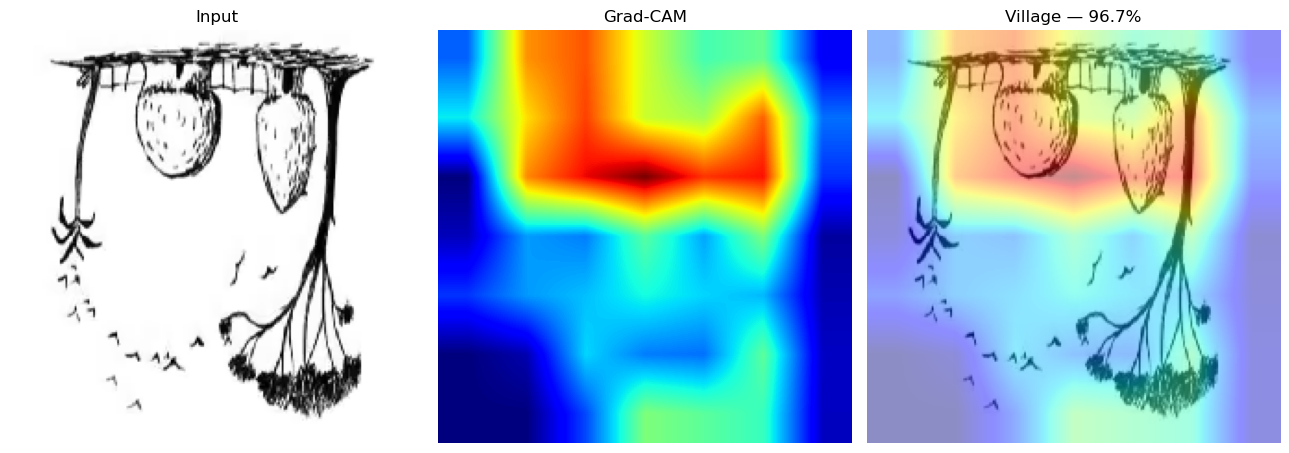

('Village', 0.9665327699368965)

In [8]:
show_gradcam("../Test Images/Real Test Rotate.png")

# Check Extra Images

Found 187 files belonging to 2 classes.
Using 150 files for training.
Using 37 files for validation.


/var/folders/cp/wp9c4zrn6xz0wxdm5dqfntvm0000gn/T/ipykernel_95555/1489472498.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  ax.imshow(cm.get_cmap("jet")(heat)[..., :3], alpha=0.4)


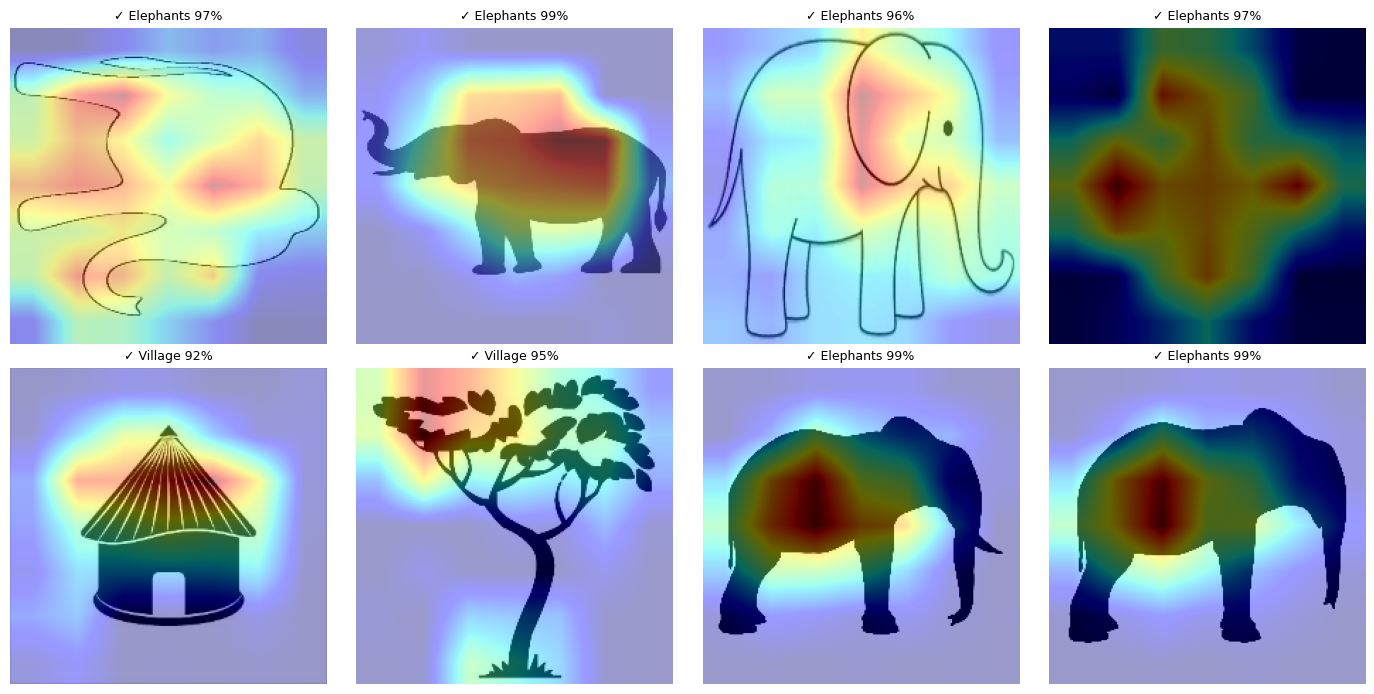

In [9]:
# rebulds the dataset split batch of 8 for check
_, raw_val = image_dataset_from_directory(
    "Data", labels='inferred', label_mode='binary',
    image_size=IMG_SIZE, batch_size=8,
    validation_split=VAL_SPLIT, subset='both',
    shuffle=True, seed=19)

# pulls a batch of images and their labels
images, labels_true = next(iter(raw_val))

# make a 2x4 grid of images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

# go through each image
for img, true_lbl, ax in zip(images, labels_true, axes.flat):
    # converts single image to batch, as done before
    batch = img.numpy()[None, ...]
    # classifies image and gets logit
    logit = float(classifier.predict(batch, verbose=0)[0][0])
    # convert to probability
    prob  = 1 / (1 + np.exp(-logit))
    # picks predicted class
    idx   = int(prob > 0.5)
    # builds the heatmap for the predicted class
    heat  = grad_cam(batch, idx)

    # draws the image using 0-255 integers
    ax.imshow(img.numpy().astype("uint8"))
    # overlays the heatmap with 40% opacity
    ax.imshow(cm.get_cmap("jet")(heat)[..., :3], alpha=0.4)
    # add icon for correct/indirect prediction
    ok = "✓" if idx == int(true_lbl[0]) else "✗"
    #adds title
    ax.set_title(f"{ok} {CLASS_NAMES[idx]} {max(prob,1-prob):.0%}", fontsize=9)
    #turn off axis
    ax.axis("off")

# fix spacing
plt.tight_layout()
# show plots
plt.show()

This model seems pretty good, it acurately classified all test images, and was confused about the water bottle

Classifys the test image as village everytime, even when inverted